
# 04 因子日历 2024：核心笔记（方法型解读）

> **本笔记要解决的问题**：打开一张因子日历，颜色深浅到底在说什么？哪一格值得追、哪一格只是噪声？每天只花 10 分钟，怎样用它监控自己的因子库，而不是被一张彩图带着走？

> **关于原书**：《因子日历 2024》（量化投资与机器学习）的原 PDF 是**纯图片扫描件，没有文字层**。本笔记**不逐页复刻、不引用书中的具体数值、图表与页面内容**，只按“因子日历/因子监控”这类工具的常见用法，讲清**怎么读、怎么用、怎么落地**。文中出现的因子名、收益、相关性与 IC 全部是**合成教学数据**，仅用于演示方法，不代表任何真实市场。

## 本章导读

因子日历不是一本“选股秘籍”，而是一张**监控面板**：把很多因子的每日/每月表现压缩到一页纸上，让人一眼看到“谁在赚、谁在亏、谁忽然不灵了”。它的价值在**发现问题**，不在**直接下单**。

本笔记分四块：

1. **是什么**：因子日历由哪些表、哪些指标拼成，它回答什么、不回答什么；
2. **怎么读**：单日/月度收益、累计净值、回撤、胜率、滚动 Sharpe/IC、相关性、风格轮动与拥挤度，以及四种最常见的误读；
3. **怎么用**：一人量化的每日 10 分钟检查表、月度复盘、失效/拥挤预警，和因子库、标签库、实盘归因怎么接；
4. **数据与实现**：交易日历、缺失日、复权/换月、滚动窗口、热力图的实现要点。

**一句话**：日历用来看“变化”，不用来“推荐”。看到异常先问“数据对吗、口径变了吗”，再问“因子是不是失效了”。

### 学习目标

- 给定一组因子的日频收益，能排出月度收益表、累计净值、回撤、胜率与滚动 Sharpe，并说清每个指标在监控里负责什么。
- 给定一张日历热力图，能读出颜色尺度、分位与异常值，指出哪些格子是短期噪声、哪些可能是结构变化。
- 给定多个因子的日收益矩阵，能算相关性与一个简单的拥挤度代理，并判断“分散化是不是真的”。
- 给定一个因子库，能写出每日 10 分钟检查表与月度复盘清单，把日历异常转成具体动作（加/减/停/观察）。
- 给定一份合成面板，能自己画出日历热力图、累计净值/回撤图、滚动 60 日 Sharpe 与滚动 IC。
- 能指出因子日历最常见的四种误读，并说明每种误读会怎样误导实盘决策。

### 先修

第 03 章的单因子报告与截面分组；第 11 章的滚动验证思想；第 17 章的因子生命周期；会 pandas 的 `groupby`、`rolling`、`pivot_table` 与 matplotlib 热力图。

## 在量化研究中的位置

- **谁用**：因子研究员、一人量化交易者、组合经理、风控。
- **输入**：日频因子收益（或因子多空组合收益）、交易日历、因子定义与版本、可选：因子得分与未来收益（算 IC）。
- **输出**：月度收益表、日历/热力图、累计净值与回撤、滚动 Sharpe/IC、相关性矩阵、拥挤度观察、异常清单与动作。
- **在流程的哪一步**：位于“因子库/回测”之后、“组合与实盘”之前；它不产生新因子，只负责持续确认旧因子还活着。
- **失败模式**：把单日大红大绿当信号、颜色尺度不一致导致误判、缺失日当 0 收益、事后只挑好看的因子做日历。
- **最小工作流**：对齐日历 → 算日收益 → 月度表/热力图 → 净值/回撤/滚动指标 → 相关性/拥挤度 → 异常清单 → 月度复盘。

### 环境准备



In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 160)
print("numpy", np.__version__, "| pandas", pd.__version__)
print("本笔记全部数据为合成教学数据，仅演示方法")


numpy 2.4.4 | pandas 3.0.2
本笔记全部数据为合成教学数据，仅演示方法



## 1. 因子日历是什么

### 1.1 一张表变成一面墙

把因子想成一排“选手”，日历就是每天给每位选手记一次成绩：

- 行：因子（价值、动量、低波、质量、carry……）；
- 列：日期或月份；
- 值：单日收益、月度收益、累计净值、回撤、波动、相关性与拥挤度。

单看一个因子的日收益曲线，很难同时比较十个因子；排成日历后，人眼能快速扫描“哪一行整体在亏、哪一列大家一起跌、哪一格突然发红”。这就是日历的核心价值：**横向比较、纵向看时间**。

### 1.2 三种常见形态

| 形态 | 横轴 | 用途 | 适合频率 |
|---|---|---|---|
| 日历热力图 | 周 × 星期 | 看某因子一个月的“哪几天”赚钱 | 日频 |
| 月度收益表 | 因子 × 月份 | 看谁稳定、谁靠一两个月 | 月频 |
| 因子仪表盘 | 净值/回撤/Sharpe/IC/相关性 | 看因子还活着吗、和其他因子挤不挤 | 日/月频 |

一人量化不必做全套。最小可用组合是：**一张月度热力图 + 一张累计净值/回撤图 + 一张相关性表**。

### 1.3 它回答什么、不回答什么

它**能**回答：哪个因子最近在亏、亏多久了；几个因子是不是在同时回撤（分散化失效）；某个因子近期收益是不是明显偏离自己的历史（异常）；因子之间的相关性是不是在上升（拥挤）。

它**不能**回答：下个月哪个因子会涨；某个因子贵不贵、能不能买；单日颜色深是不是因为数据错误。**日历是后视镜和仪表盘，不是导航。**

### 1.4 数据契约：先对齐，再画图

画日历之前，先把数据对齐成“因子 × 交易日”的矩阵：

| 项目 | 要点 | 不处理会怎样 |
|---|---|---|
| 交易日历 | 用交易日，不用自然日 | 周末/节假日被当成 0 收益 |
| 缺失日 | 停牌/无数据记为 NaN，不填 0 | 把“没有数据”当成“没涨没跌” |
| 复权 | 股票因子用复权收益 | 除权日出现假跌 |
| 换月 | 期货因子用换月调整后的连续收益 | 换月跳空被当成因子收益 |
| 因子版本 | 记录因子定义/参数版本 | 口径变了却和历史比较 |

下面的合成面板按“12 个因子 × 2024 年 250 个交易日”生成，并用工作日近似交易日（真实交易日需按交易所日历剔除节假日）：



In [2]:

rng = np.random.default_rng(20240101)
dates = pd.bdate_range("2024-01-01", periods=250)
factors = ["价值", "动量", "低波", "质量", "成长", "规模",
           "反转", "carry", "基差", "波动率", "偏斜", "拥挤"]
mu_annual = rng.normal(0.06, 0.04, size=12)
sigma_annual = rng.uniform(0.06, 0.20, size=12)
factor_daily = pd.DataFrame(
    rng.normal(mu_annual / 252, sigma_annual / np.sqrt(252), size=(len(dates), 12)),
    index=dates,
    columns=factors,
)
# 人为构造一个“下半年失效”的因子，用来演示日历上怎么发现它
late = dates >= pd.Timestamp("2024-07-01")
factor_daily.loc[late, "动量"] = factor_daily.loc[late, "动量"] - 0.0015

# 合成 12 个因子的日度 IC：60 只资产、因子得分与次日收益弱相关
n_assets = 60
ic_cols = {}
for f in factors:
    score = pd.DataFrame(rng.normal(size=(len(dates), n_assets)), index=dates)
    fwd = 0.03 * score + pd.DataFrame(rng.normal(size=(len(dates), n_assets)), index=dates, columns=score.columns)
    ic_cols[f] = score.rank(axis=1).corrwith(fwd.rank(axis=1), axis=1)
ic_daily = pd.DataFrame(ic_cols)

print("因子日收益矩阵:", factor_daily.shape, "| 交易日:", dates[0].date(), "->", dates[-1].date())
print("日度 IC 矩阵:", ic_daily.shape, "| 平均 IC:", round(float(ic_daily.mean().mean()), 4))
print(factor_daily.round(4).head(3).to_string())


因子日收益矩阵: (250, 12) | 交易日: 2024-01-01 -> 2024-12-13
日度 IC 矩阵: (250, 12) | 平均 IC: 0.0254
                价值      动量      低波      质量      成长      规模      反转   carry      基差     波动率      偏斜      拥挤
2024-01-01  0.0147  0.0122 -0.0006  0.0109 -0.0008 -0.0066  0.0005  0.0000 -0.0033  0.0111 -0.0156 -0.0107
2024-01-02 -0.0105 -0.0117  0.0010  0.0041 -0.0038  0.0042  0.0009  0.0007  0.0149 -0.0082 -0.0003 -0.0026
2024-01-03 -0.0017  0.0285 -0.0032 -0.0067 -0.0077 -0.0045  0.0065  0.0070 -0.0044 -0.0035  0.0008 -0.0014



**读数与应用**：`factor_daily` 是 250 行 × 12 列，行是交易日、列是因子；`ic_daily` 是每天、每个因子的截面 Rank IC。平均 IC 只有 0.02 左右——这是合成数据里“弱相关”的量级，真实市场的 IC 也常常很小，所以**看 IC 要看稳定性，不要看单日高低**。

**常见错误**：

1. 用自然日当列，周末全是 0，月度胜率被拉高；
2. 缺失日填 0，把“没数据”当成“没波动”；
3. 合成/回测数据和实盘数据混在一起画日历，颜色尺度对不上。

## 2. 怎么读

### 2.1 单日看噪声，月度看方向

单日收益的波动很大，一天的颜色说明不了什么。先把日收益按月汇总：

$$\text{月度收益}=\prod_{t\in\text{月}}(1+r_t)-1.$$

一个因子一年只有 12 个月度观测，月份尺度的“连续三个月同向”比单日涨跌更值得注意。日历热力图适合看“哪几天”，月度表适合看“哪几个月”，两者不要混着解读。

### 2.2 累计净值与回撤：路径比终点重要

累计净值把收益连乘起来：

$$\text{NAV}_t=\prod_{s\le t}(1+r_s).$$

回撤回答“从最高点跌下来多少”：

$$\text{DD}_t=1-\frac{\text{NAV}_t}{\max_{s\le t}\text{NAV}_s}.$$

两个因子年末收益相同，一个一路向上、一个年中腰斩后反弹，日历上看到的是完全不同的风险。**监控看回撤，不只看收益。**

### 2.3 胜率、滚动 60 日 Sharpe/IC

- 胜率：日收益 > 0 的比例，便宜、直观，但会被小涨小跌平均掉；
- 滚动 Sharpe：$\text{mean}(r_{t-59:t})/\text{std}(r_{t-59:t})\times\sqrt{252}$，看近期风险调整后收益；
- 滚动 IC：每日截面 Rank IC 的 60 日均值，看预测力是否稳定。

滚动窗口的意义是“用最近 60 天回答最近还灵不灵”。窗口太短会全是噪声，太长会掩盖变化；60 日是常见起点，不是固定答案。

### 2.4 相关性：分散化是不是真的

两张日历并排看，很容易误以为“两个因子都在赚，所以分散化好”。真正要看的是**相关性**：如果两个因子在危机月份同时大亏，它们的相关性会在那时上升，分散化在最需要的时候失效。**相关性不是常数，日历上要重点看“一起变红”的月份。**

### 2.5 风格轮动与拥挤度

风格轮动表现为“某几行连续几个月很亮，另几行连续很暗”。拥挤度没有唯一公式，监控里常用**代理指标**：例如“近 20 日累计收益 ÷ 近一年波动”，值越高说明近期涨幅相对自身波动越极端，值得警惕，但不能直接当“要反转”的信号。

### 2.6 四种常见误读

1. **颜色尺度不一致**：一张图 vmin=-1%、另一张 vmin=-10%，同样的红看起来完全不同；
2. **把短期噪声当信号**：单日或单周的最深色格，大概率是噪声；
3. **缺失日当 0**：空白和“横盘”在日历上必须区分；
4. **事后挑因子**：只把今年表现好的因子放进日历，等于自我欺骗。

下面先做月度表与胜率，再做两张日历图：



In [3]:

monthly = (1 + factor_daily).groupby(factor_daily.index.to_period("M")).prod() - 1
monthly.index = monthly.index.astype(str)
summary = pd.DataFrame(
    {
        "月均收益%": monthly.mean() * 100,
        "月胜率": (monthly > 0).mean(),
        "日胜率": (factor_daily > 0).mean(),
        "年化波动%": factor_daily.std() * np.sqrt(252) * 100,
    }
).round(3)
print("月度收益（%）")
print((monthly * 100).round(2).to_string())
print()
print("因子汇总（按 2024 年月均收益排序）")
print(summary.sort_values("月均收益%", ascending=False).to_string())


月度收益（%）
            价值     动量    低波    质量    成长    规模    反转  carry     基差   波动率    偏斜    拥挤
2024-01   9.30   8.58 -2.40 -0.88 -0.66 -4.08  0.24   5.65  11.89  2.44 -0.29  5.22
2024-02  -1.54  -3.22 -0.18  0.36 -5.93 -0.90 -0.36   7.97  10.21  6.29  1.54 -0.74
2024-03   5.04  -2.26  4.15  0.72  3.48  1.16  1.69  -4.05  -0.22 -6.14  6.78  1.51
2024-04   8.33  -3.15 -0.70 -2.66  3.62  8.70  2.74   6.97   0.24  1.95  1.92 -6.33
2024-05  11.23  11.55 -2.50  0.18 -3.09 -2.10  0.69   1.11   2.58  3.66  5.73  3.38
2024-06   0.11 -10.17 -1.90 -0.09  3.26  5.52  3.97   1.88  13.84  6.49 -1.86 -1.54
2024-07   1.96  -0.74  0.70 -6.27  0.42 -2.11 -2.32   0.83   3.59  7.61  3.06  5.44
2024-08  -2.91   8.14 -1.15  1.30 -4.43  5.88  0.89   2.99  13.96  8.19 -0.58  4.20
2024-09   2.91 -11.26 -2.11 -1.23 -2.44  2.32  0.06  10.11   3.40 -7.09  2.03  4.19
2024-10  -2.91   3.79  0.22 -3.89 -6.87  1.35  1.75  -3.71   1.07  2.24  2.70  1.69
2024-11  -3.84  -1.40 -1.59  7.65  2.36 -1.58 -0.07   1.40  -0.47  0


**读数与应用**：月度表把 250 天压缩成 12 个数，`月胜率` 和 `日胜率` 一起看。例如“动量”日胜率 0.508、月胜率只有 0.417、全年月均收益接近 0——它靠小涨积累，却被少数大跌抹掉。**排序只是排序，不能当“明年买什么”的结论。**



### 2.7 日历热力图怎么画、怎么看

日历热力图的画法很简单：把日期拆成“第几周 × 星期几”，把收益填进格子。读的时候注意三点：一是**同一张图内颜色尺度必须固定**（例如单日收益 -2% 到 +2%），否则跨月比较会失真；二是**空白格是缺失日**，不是 0；三是**看行列模式**——某一行整周发红，比单个深色格更值得注意。

下面画两张图：一张是“价值”因子 2024 年 6 月的日历热力图，一张是 12 个因子 × 12 个月的月度热力图。



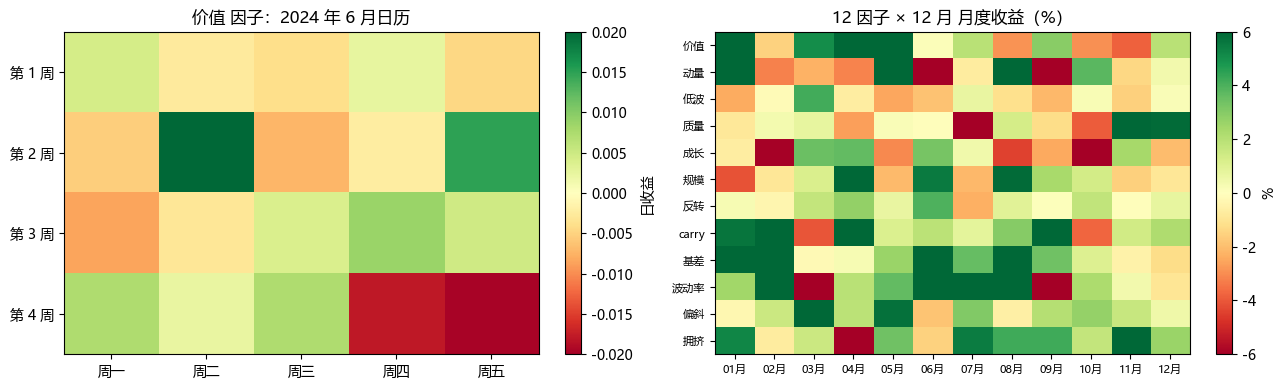

2024-06 价值因子日收益（%）:
2024-06-03    0.42
2024-06-04   -0.26
2024-06-05   -0.39
2024-06-06    0.24
2024-06-07   -0.46
2024-06-10   -0.54
2024-06-11    2.16
2024-06-12   -0.73
2024-06-13   -0.23
2024-06-14    1.49
2024-06-17   -0.85
2024-06-18   -0.31
2024-06-19    0.38
2024-06-20    0.86
2024-06-21    0.47
2024-06-24    0.73
2024-06-25    0.23
2024-06-26    0.73
2024-06-27   -1.79
2024-06-28   -1.96
Freq: B


In [4]:

f = "价值"
m = factor_daily[f].loc["2024-06-01":"2024-06-30"]
cal = pd.DataFrame(
    {
        "week": (m.index.day - 1) // 7 + 1,
        "weekday": m.index.weekday,
        "ret": m.values,
    }
)
grid = cal.pivot_table(index="week", columns="weekday", values="ret").reindex(columns=range(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
im0 = axes[0].imshow(grid.values, cmap="RdYlGn", vmin=-0.02, vmax=0.02, aspect="auto")
axes[0].set_xticks(range(5))
axes[0].set_xticklabels(["周一", "周二", "周三", "周四", "周五"])
axes[0].set_yticks(range(len(grid.index)))
axes[0].set_yticklabels([f"第 {w} 周" for w in grid.index])
axes[0].set_title(f"{f} 因子：2024 年 6 月日历")
plt.colorbar(im0, ax=axes[0], fraction=0.046, label="日收益")

im1 = axes[1].imshow((monthly * 100).T.values, cmap="RdYlGn", vmin=-6, vmax=6, aspect="auto")
axes[1].set_xticks(range(len(monthly.index)))
axes[1].set_xticklabels([str(mo)[-2:] + "月" for mo in monthly.index], fontsize=8)
axes[1].set_yticks(range(len(factors)))
axes[1].set_yticklabels(factors, fontsize=8)
axes[1].set_title("12 因子 × 12 月 月度收益（%）")
plt.colorbar(im1, ax=axes[1], fraction=0.046, label="%")
plt.tight_layout()
plt.show()
print("2024-06 价值因子日收益（%）:")
print((m * 100).round(2).to_string())



**读数与应用**：左图每天一格，空白是周末/非交易日；右图一眼能看出哪几个月整列偏红（系统性冲击）或哪一行持续偏红（该因子走弱）。**不要把相邻两张图的颜色深浅直接对比——先看色标范围是否相同。**

**常见错误**：把月度表和日历图画在同一色标下、缺失日填 0、跨因子用不同的 vmin/vmax。

## 3. 用日历做监控：一人量化的每日与月度流程

### 3.1 每日 10 分钟检查表

1. **看异常格**：今天有没有因子的日收益超过自身 3 倍标准差？
2. **看同步性**：是不是很多因子一起红（大盘/风格冲击）？还是一两个因子单独异常（可能是因子本身或数据问题）？
3. **看数据**：异常日的行情、停牌、换月、复权有没有问题？
4. **看持仓**：实盘组合对这些因子的暴露有多大，异常是否影响今天下单？
5. **记一笔**：把异常写进观察日志（日期、因子、幅度、初判原因、动作）。

10 分钟的目标不是“找到机会”，而是“排除数据错误、识别真实异常”。

### 3.2 月度复盘

每月末花 30 分钟回答五个问题：

1. 哪些因子的滚动 60 日 Sharpe 由正转负、或持续为负？
2. 哪些因子的滚动 IC 明显走低（预测力下降）？
3. 因子间相关性有没有系统性上升？
4. 日历上的异常，事后证明是数据问题还是因子变化？
5. 下个月的因子权重/观察名单怎么调？

### 3.3 失效与拥挤预警（示例阈值）

- 失效预警：滚动 60 日 Sharpe < -0.5，且连续 2 个月为负 → 降权或暂停；
- 预测力预警：滚动 60 日 IC 均值低于历史 20% 分位 → 观察；
- 拥挤预警：拥挤度代理进入历史 90% 分位，且相关性上升 → 降低集中度；
- 数据预警：单日收益超过 5 倍标准差 → 先查数据，再查市场。

阈值只是示例，必须用自己的因子库历史分布来标定；**预警不是自动交易信号，而是“该看一眼”的提醒**。

### 3.4 和因子库、标签库、实盘归因连接

- **因子库**：日历里每个因子必须能对应到定义、参数、版本；口径变了要在日历上标出来；
- **标签库**：因子好不只看收益，还要看它对标签（未来 1/5/20 日收益）的 IC；日历与 IC 要一起看；
- **实盘归因**：日历上的因子收益是“理论多空组合”，实盘组合有约束、成本和风格暴露，二者差异要能解释。

下面把累计净值、回撤、滚动 Sharpe 画出来：



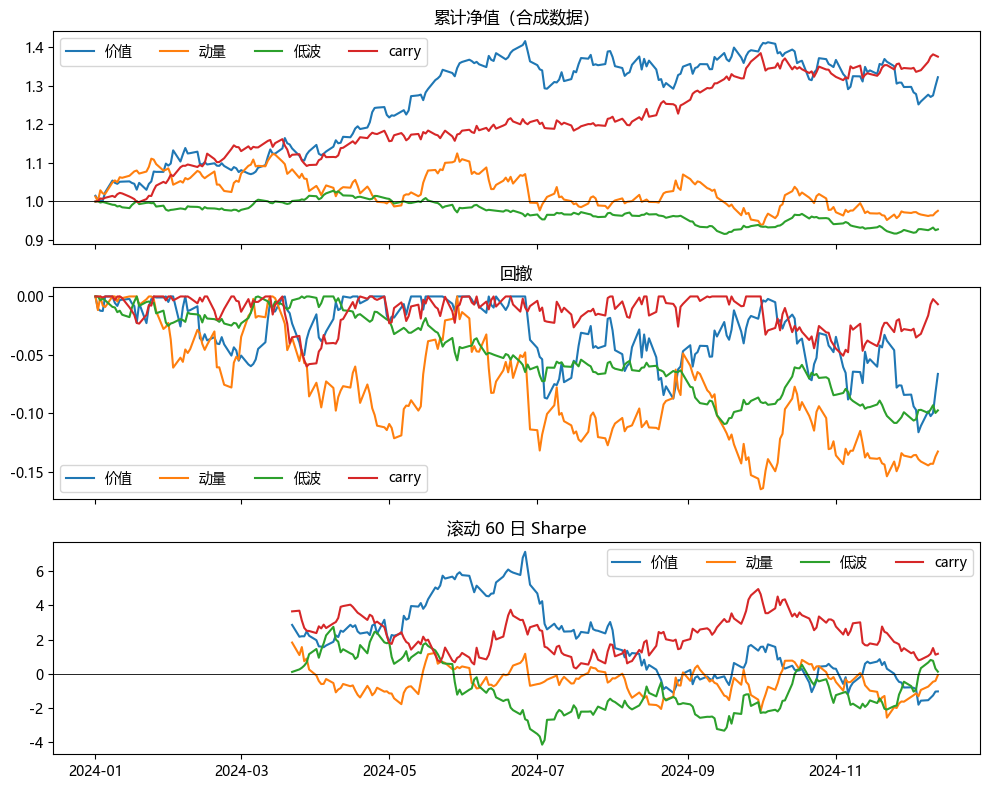

年末净值: {'价值': 1.322, '动量': 0.976, '低波': 0.928, 'carry': 1.376}
全年最大回撤: {'价值': -0.1162, '动量': -0.1649, '低波': -0.1091, 'carry': -0.0599}


In [5]:

nav = (1 + factor_daily).cumprod()
drawdown = nav / nav.cummax() - 1
roll_sharpe = factor_daily.rolling(60).mean() / factor_daily.rolling(60).std() * np.sqrt(252)
show = ["价值", "动量", "低波", "carry"]

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for f in show:
    axes[0].plot(nav.index, nav[f], label=f)
axes[0].set_title("累计净值（合成数据）")
axes[0].axhline(1.0, color="black", linewidth=0.6)
axes[0].legend(ncol=4)
for f in show:
    axes[1].plot(drawdown.index, drawdown[f], label=f)
axes[1].set_title("回撤")
axes[1].legend(ncol=4)
for f in show:
    axes[2].plot(roll_sharpe.index, roll_sharpe[f], label=f)
axes[2].axhline(0.0, color="black", linewidth=0.6)
axes[2].set_title("滚动 60 日 Sharpe")
axes[2].legend(ncol=4)
plt.tight_layout()
plt.show()

print("年末净值:", nav.iloc[-1][show].round(3).to_dict())
print("全年最大回撤:", drawdown.min()[show].round(4).to_dict())



**读数与应用**：年末净值：carry 1.376、价值 1.322、动量 0.976、低波 0.928；动量的全年最大回撤约 -16.5%。再看滚动 Sharpe 会发现它在年内多次穿越 0——单看某一段，结论可能完全相反。**这就是仪表盘该做的事：把“最近还灵不灵”画出来，而不是预测。**

## 4. 数据与实现要点

### 4.1 交易日历与缺失日

交易日历必须来自交易所或数据源，不能用 `pd.date_range` 的自然日凑；国内还要处理夜盘归属（夜盘算下一个交易日）。缺失日保留 NaN，画图时用单独颜色或留白，不要填 0。

### 4.2 复权、换月与停牌

股票收益用复权价；期货因子用换月调整后的连续合约收益，且要在日历上标出换月日——换月当天的跳空不是因子收益。停牌日没数据，不能当成“当天收益为 0”。

### 4.3 滚动窗口与最小样本

滚动 60 日 Sharpe/IC 的前 59 天是 NaN，这是正常的；不要在样本不足时强行画线。窗口长度要与因子的持有期匹配：日内因子用短窗口，月度因子用长窗口，**看趋势变化而不是精确数值**。

### 4.4 实现清单

1. 先把收益对齐到同一交易日历；
2. 月度收益用连乘，不用求和；
3. 热力图统一颜色尺度（同一指标同一范围）；
4. 异常判定用滚动分位/标准差，不用“看起来红”；
5. 每张图旁边写下“口径、窗口、数据版本”。

最后算相关性与滚动 IC，并做一个简单的拥挤度代理：



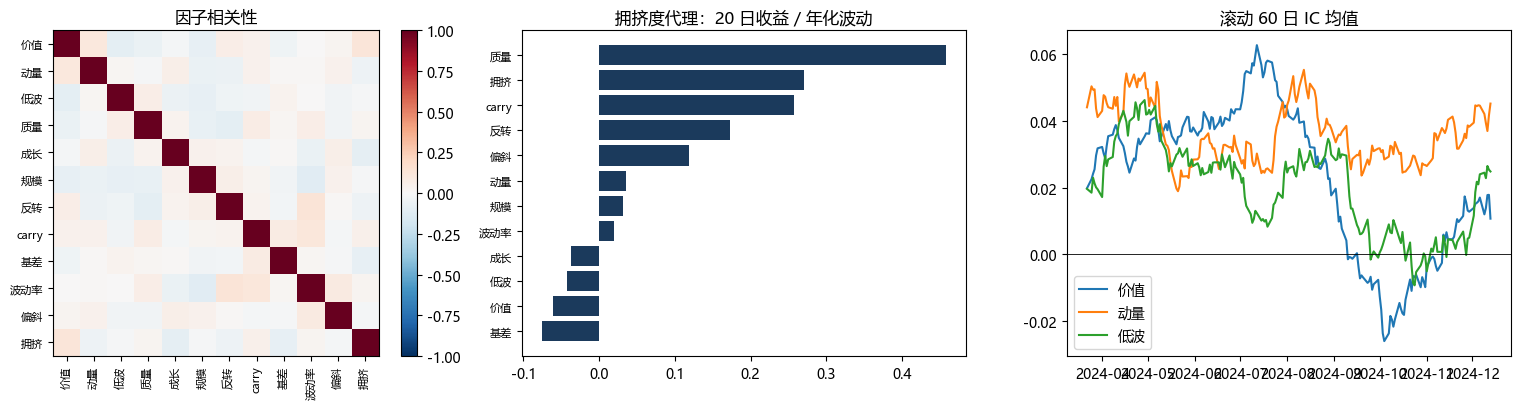

相关性最高的三对因子:
反转     波动率    0.130
价值     拥挤     0.121
carry  波动率    0.114
拥挤度代理最高的三个因子: {'质量': 0.46, '拥挤': 0.27, 'carry': 0.26}
年末滚动 60 日 IC: {'价值': 0.011, '动量': 0.045, '低波': 0.025}


In [6]:

corr = factor_daily.corr()
crowd = factor_daily.tail(20).sum() / (factor_daily.rolling(250).std().iloc[-1] * np.sqrt(252))
roll_ic = ic_daily.rolling(60).mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
im = axes[0].imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(factors)))
axes[0].set_xticklabels(factors, rotation=90, fontsize=8)
axes[0].set_yticks(range(len(factors)))
axes[0].set_yticklabels(factors, fontsize=8)
axes[0].set_title("因子相关性")
plt.colorbar(im, ax=axes[0], fraction=0.046)

order = crowd.sort_values().index
axes[1].barh(order, crowd[order].values, color="#1B3A5C")
axes[1].set_title("拥挤度代理：20 日收益 / 年化波动")
axes[1].tick_params(axis="y", labelsize=8)

for f in ["价值", "动量", "低波"]:
    axes[2].plot(roll_ic.index, roll_ic[f], label=f)
axes[2].axhline(0.0, color="black", linewidth=0.6)
axes[2].set_title("滚动 60 日 IC 均值")
axes[2].legend()
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("相关性最高的三对因子:")
print(upper.sort_values(ascending=False).head(3).round(3).to_string())
print("拥挤度代理最高的三个因子:", crowd.sort_values(ascending=False).head(3).round(2).to_dict())
print("年末滚动 60 日 IC:", roll_ic.iloc[-1][["价值", "动量", "低波"]].round(3).to_dict())



**读数与应用**：这张合成数据里因子间相关性普遍不高（最高约 0.13），说明两两分散化尚可；真实数据里要重点看危机月份的相关性是否跳升。拥挤度代理只是一个观察值（本例最高的是“质量”约 0.46），不能单独下结论。滚动 IC 图比单日 IC 更适合放进月报：**看的是 60 日的方向，不是某一天的尖刺。**

## 本章小结

### 一张表

| 问题 | 看什么 | 怎么判断 |
|---|---|---|
| 今天正常吗 | 日收益异常格、同步性 | 超过 3–5 倍标准差先查数据 |
| 这个月谁在赚 | 月度收益表、月胜率 | 连续同向比单月最大更重要 |
| 还活着吗 | 累计净值、回撤、滚动 Sharpe | 由正转负且持续 → 降权观察 |
| 预测力还在吗 | 滚动 60 日 IC | 低于历史低分位 → 观察 |
| 分散化真吗 | 相关性矩阵、一起变红的月份 | 危机时相关性上升要警惕 |
| 拥挤吗 | 拥挤度代理、相关性趋势 | 极端分位要降低集中度 |
| 数据对吗 | 缺失日、换月、复权标记 | 空白≠0，换月≠因子收益 |

### 八句话

1. 日历是监控面板，不是选因子信号。
2. 单日看噪声，月度看方向。
3. 路径和回撤比年末收益更重要。
4. 滚动 60 日 Sharpe/IC 看“最近还灵不灵”。
5. 相关性会在危机时上升，分散化会失效。
6. 拥挤度是观察指标，不是反转信号。
7. 缺失日不要填 0，换月要标记。
8. 看到异常先查数据，再谈因子失效。

## 本章习题

**1.** 因子日历通常由哪三类表/图组成？各自负责什么？

**2.** 为什么月度收益要用连乘算，而不能把日收益直接相加？

**3.** 某因子 2024 年日胜率 55%、月胜率 42%，可能说明什么？

**4.** 滚动 60 日 Sharpe 的计算公式是什么？窗口长度为什么不能太短或太长？

**5.** 两个因子的净值都创新高，为什么还可能要担心分散化？

**6.** 因子日历最常见的四种误读是什么？

**7.** 某因子单日收益是 5 倍标准差，你应该先做什么？

**8.** 一人量化的每日 10 分钟检查表，最重要的是哪两步？

<details><summary>参考答案</summary>

**1.** 日历热力图（看某因子一个月里哪几天赚）、月度收益表（看因子×月份）、因子仪表盘（净值/回撤/Sharpe/IC/相关性）。

**2.** 收益是比率，跨期要连乘：$(1+r_1)(1+r_2)-1$，直接相加会忽略复利与波动拖累。

**3.** 日胜率高但月胜率低，说明它靠小涨积累、被少数大跌抹掉；收益分布偏斜，尾部风险大。

**4.** $\text{mean}(r_{t-59:t})/\text{std}(r_{t-59:t})\times\sqrt{252}$；太短全是噪声，太长会掩盖近期的结构性变化。

**5.** 因为相关性可能在上升、且危机月份同时回撤；净值的“终点”看不出“一起红”的过程。

**6.** 颜色尺度不一致；把短期噪声当信号；缺失日当 0；事后只挑表现好的因子。

**7.** 先查数据（停牌、换月、复权、时间戳），确认不是数据错误后再看市场/因子本身。

**8.** 看异常格（找单因子异常）与看同步性（区分系统性冲击还是个别因子问题），再查数据、看持仓、记录。

</details>

---

## 参考资料

- 《因子日历 2024》，量化投资与机器学习（原 PDF 为纯图片扫描件，无文字层；本笔记为**基于因子日历常见用法的方法型解读，不逐页复刻**）。
- 因子监控通用方法：滚动 Sharpe/IC、最大回撤与水下时间、因子相关性与风格轮动、因子拥挤度代理指标。
- 本书系其他书目：01 七因子投资、02 Smart Beta 与因子投资、03 因子投资方法与实践。
- 因子库与标签库相关章节：第 11、15、17、40 章。
